<a href="https://colab.research.google.com/github/achmadanval/PCVK-2026/blob/main/PCVK_P5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

NAMA : Achmad Anval Adhiem Allain
NIM : 244107020039 | N = 39
bins   : 64
clip   : 3.0
tile   : 5
L      : 2
WAKTU : 2026-09-27 22:31:15 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN : 7d7cbf9debaf8553


Text(0.5, 1.0, '244107020039 - CLAHE clip 3.0')

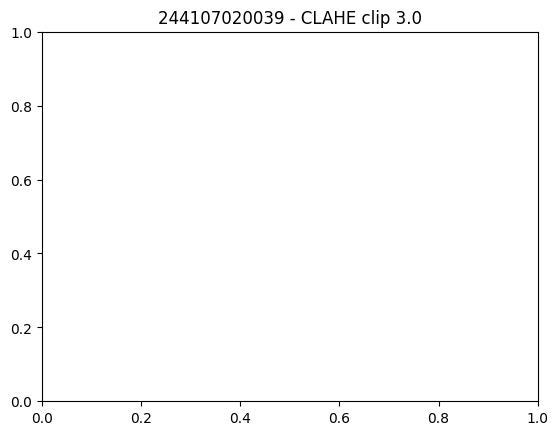

In [ ]:
# ===== SEL IDENTITAS - JANGAN DIHAPUS, HARUS SEL PERTAMA =====
import sys, platform, hashlib, datetime, zoneinfo
NAMA = 'Achmad Anval Adhiem Allain'
NIM = '244107020039' # ganti dengan NIM Anda
N = int(NIM[-3:])
PARAM = {
 'bins' : 2 ** ((N % 4) + 3),
 'clip' : round(1.0 + (N % 5) * 0.5, 1),
 'tile' : (N % 4) + 2,
 'L' : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))
print('NAMA :', NAMA)
print('NIM :', NIM, '| N =', N)
for k, v in PARAM.items():
 print('%-6s :' % k, v)
print('WAKTU :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN :', hashlib.sha256(kunci.encode()).hexdigest()[:16])
plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import numpy as np
import matplotlib.pyplot as plt
import os
import math
import glob

Membuat Histogram Manual

<BarContainer object of 256 artists>

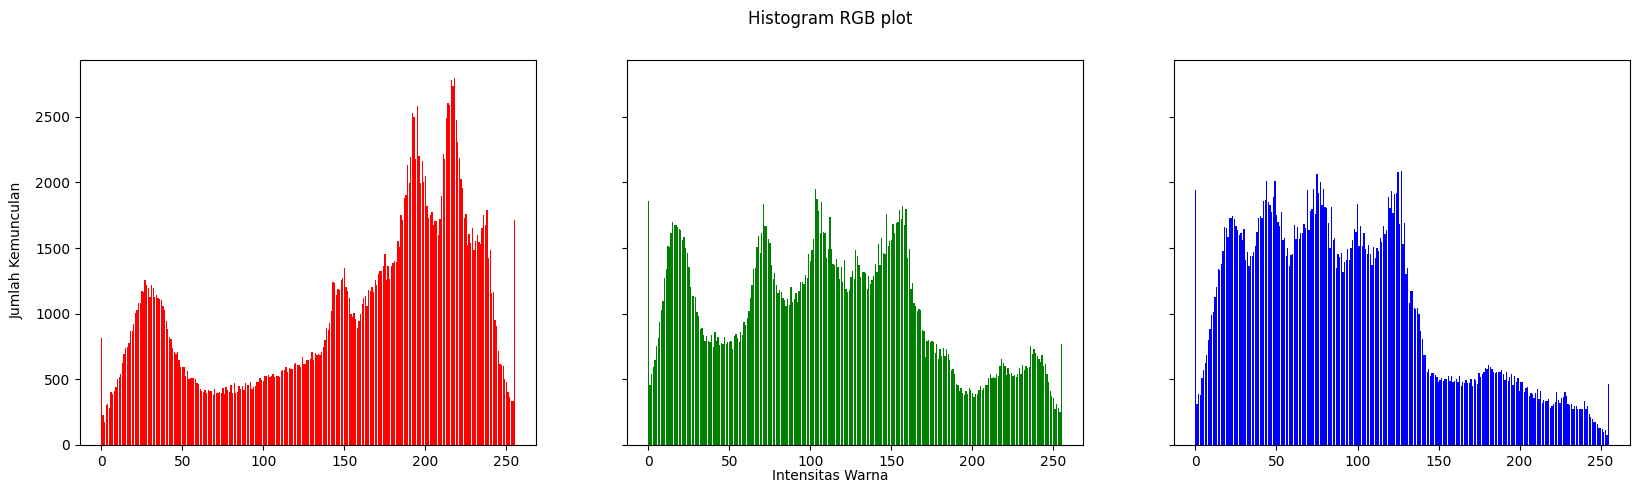

In [ ]:
img = cv.imread('/content/drive/MyDrive/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range (0, height):
  for x in range(0, width) :
    red[img[y][x][0]] += 1
    green[img[y][x][1]] += 1
    blue[img[y][x][2]] += 1

names =  np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5),sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')


PERTANYAAN PRAKTIKUM E1
1. Buatlah histogram citra yang sama menggunakan library NumPy, yaitu
numpy.histogram, dan juga cv.calcHist. Bandingkan ketiganya dengan menghitung
selisih maksimum antar hasil. Selisihnya harus nol; tampilkan pembuktiannya pada
lena.jpg lebih dulu, kemudian ulangi pada KTM1b.jpg.
2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF untuk KTM1a.jpg sampai
KTM1d.jpg dalam satu figure 2 x 2. Jelaskan perbedaan bentuk kurva CDF antara citra
paling gelap dan citra paling terang milik Anda, lalu kaitkan dengan kondisi
pencahayaan saat akuisisi pada Pertemuan 2.
3. Ulangi histogram KTM1b.jpg dengan jumlah bin sebesar PARAM['bins'] dan dengan
256 bin. Tampilkan keduanya berdampingan dan jelaskan informasi apa yang hilang
ketika jumlah bin dikurangi.

In [ ]:
def histogram_manual(img, L=256):
  h = np.zeros(L, dtype=np.int64)
  for y in range(img.shape[0]):
    for x in range(img.shape[1]):
      h[img[y,x]] += 1
  return h


def uji_perbadingan(image_path, title):

  img = cv.imread(image_path, cv.IMREAD_GRAYSCALE)

  #1. manual
  h_manual = histogram_manual(img)

  #2. Numpy
  h_numpy, _ = np.histogram(img.flatten(), bins=256, range=(0,255))

  #3. OpenCv
  h_cv = cv.calcHist([img], [0], None, [256], [0,256]).flatten()

  selisih_numpy = np.max(np.abs(h_manual - h_numpy))
  selisih_cv = np.max(np.abs(h_manual - h_cv))

  print(f"--- Pengujian pada {title} ---")
  print(f"Selisih maksimum Manual vs NumPy  : {selisih_numpy}")
  print(f"Selisih maksimum Manual vs OpenCV : {selisih_cv}\n")


uji_perbadingan('/content/drive/MyDrive/lena.jpg', '/content/drive/MyDrive/lena.jpg')
uji_perbadingan('/content/drive/MyDrive/KTM1a.jpg', '/content/drive/MyDrive/KTM1a.jpg')

--- Pengujian pada /content/drive/MyDrive/lena.jpg ---
Selisih maksimum Manual vs NumPy  : 0
Selisih maksimum Manual vs OpenCV : 0.0

--- Pengujian pada /content/drive/MyDrive/KTM1a.jpg ---
Selisih maksimum Manual vs NumPy  : 0
Selisih maksimum Manual vs OpenCV : 0.0



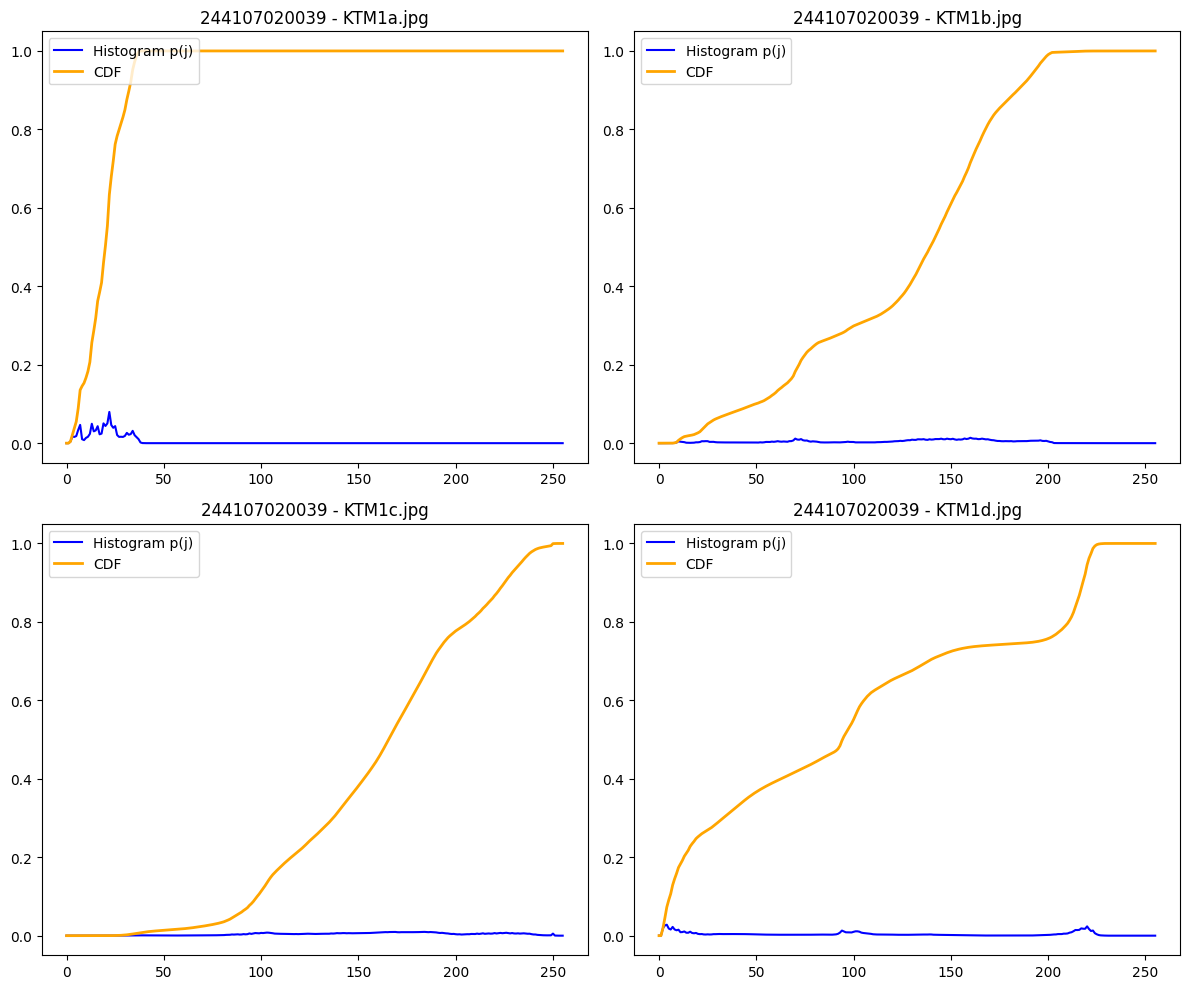

In [ ]:
citra_ktm = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
plt.figure(figsize=(12, 10))

BASE = '/content/drive/MyDrive'

for i, nama_file in enumerate(citra_ktm):
    # Baca citra grayscale
    img = cv.imread(BASE + '/' + nama_file, cv.IMREAD_GRAYSCALE)

    # Hitung p(j) dan CDF
    hist, _ = np.histogram(img.flatten(), bins=256, range=[0,256])
    p = hist / img.size
    cdf = np.cumsum(p)

    # Plotting
    plt.subplot(2, 2, i+1)
    plt.plot(p, color='blue', label='Histogram p(j)')
    plt.plot(cdf, color='orange', linewidth=2, label='CDF')
    plt.title(f"{244107020039} - {nama_file}")
    plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

KTM1a : merupakan gambar dengan citra paling gelap karena Grafik menumpuk di sebelah kiri dan datar ke kanan menunjukan bahwa citra tersebut kekurangan cahaya. Sedangkan
KTM1d : Merupakan gambar dengan citra paling terang karena grafik mengalamai lonjakan ekstrem ketika mendekati nilai 255 atau semakin ke kanan yang menandakan bahwa citra tersebut kelebihan cahaya.

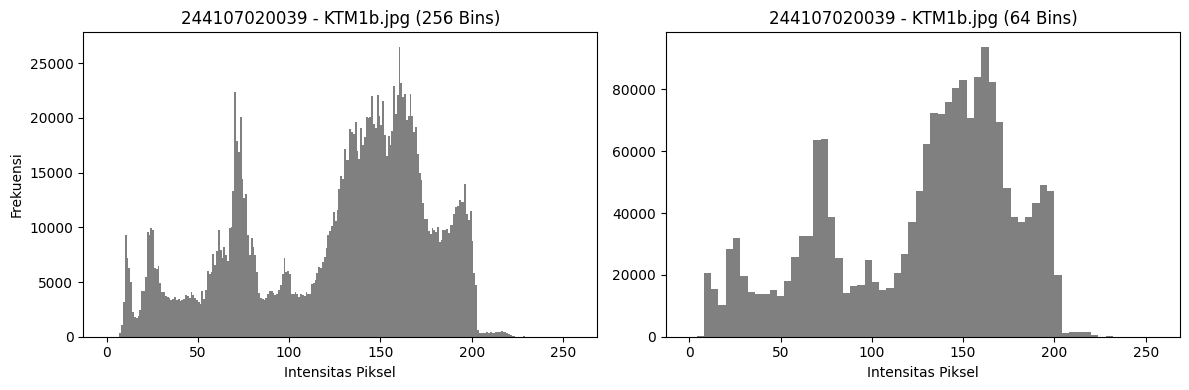

In [ ]:
img = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
bin_pribadi = PARAM['bins']

plt.figure(figsize=(12, 4))

# Plot 256 bins
plt.subplot(1, 2, 1)
plt.hist(img.flatten(), bins=256, range=[0,256], color='gray')
plt.title(f"{244107020039} - KTM1b.jpg (256 Bins)")
plt.xlabel("Intensitas Piksel")
plt.ylabel("Frekuensi")

# Plot bin dari PARAM
plt.subplot(1, 2, 2)
plt.hist(img.flatten(), bins=bin_pribadi, range=[0,256], color='gray')
plt.title(f"{244107020039} - KTM1b.jpg ({bin_pribadi} Bins)")
plt.xlabel("Intensitas Piksel")

plt.tight_layout()
plt.show()

mengubah 256 bins menjadi 32 bins akan mengorbankan ketajaman detail data demi menampilkan tren distribusi umum yang lebih sederhana.

### E2 Percobaan Histogram Equalization

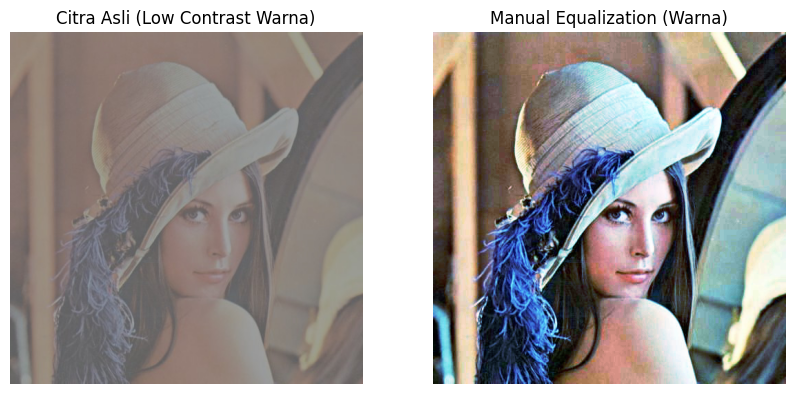

<BarContainer object of 256 artists>

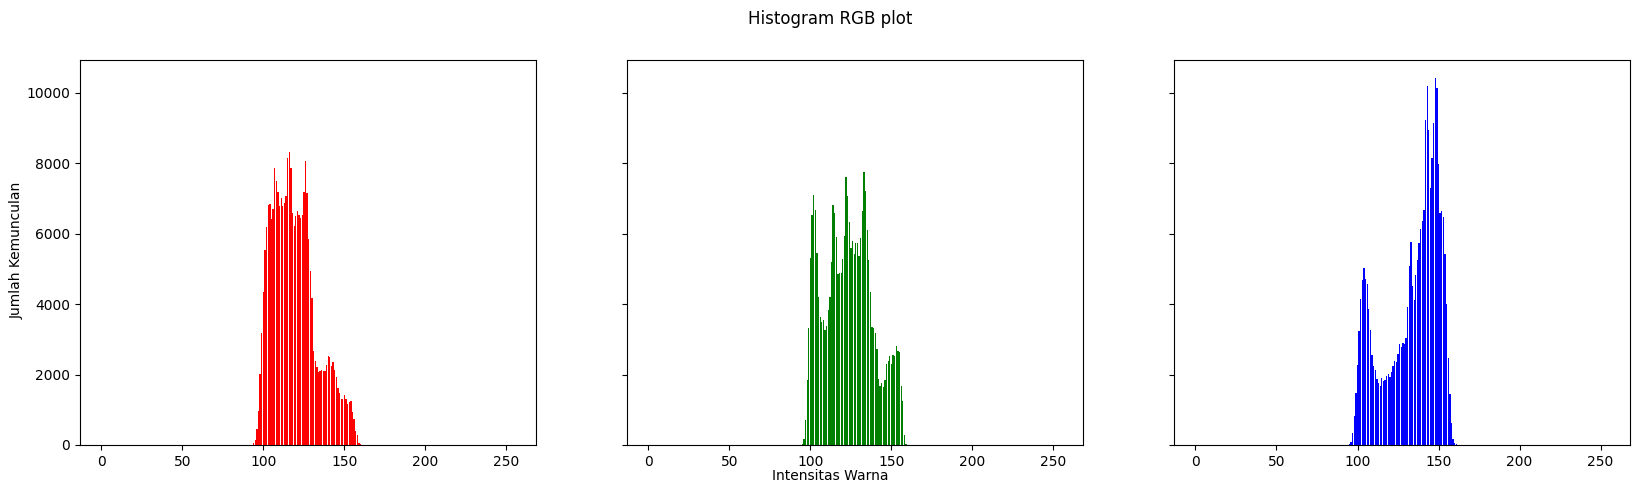

In [ ]:
FOTO = '/content/drive/MyDrive'
KTM = '/content/drive/MyDrive'


# 1. Baca citra TANPA parameter grayscale agar tetap berwarna (BGR)
img_color = cv.imread(FOTO + '/lena_lc.jpg')

# Fungsi manual untuk 1 layer (channel)
def histogram_equalization(image_channel):
    hist, bins = np.histogram(image_channel.flatten(), 256, [0, 256])
    cdf = hist.cumsum()
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
    cdf_final = np.ma.filled(cdf_m, 0).astype('uint8')
    return cdf_final[image_channel]

# 2. Pisahkan channel B, G, R
b, g, r = cv.split(img_color)

# 3. Lakukan ekualisasi manual pada setiap channel
b_eq = histogram_equalization(b)
g_eq = histogram_equalization(g)
r_eq = histogram_equalization(r)

# 4. Gabungkan kembali channel yang sudah diekualisasi
img_manual_color = cv.merge((b_eq, g_eq, r_eq))

# Menampilkan hasil (Konversi BGR ke RGB untuk Matplotlib)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv.cvtColor(img_color, cv.COLOR_BGR2RGB))
plt.title('Citra Asli (Low Contrast Warna)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv.cvtColor(img_manual_color, cv.COLOR_BGR2RGB))
plt.title('Manual Equalization (Warna)')
plt.axis('off')

plt.show()


height, width, depth = np.shape(img_color)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range (0, height):
  for x in range(0, width) :
    red[img_color[y][x][0]] += 1
    green[img_color[y][x][1]] += 1
    blue[img_color[y][x][2]] += 1

names =  np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=(20, 5),sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')


3.

In [ ]:
berkas = KTM + '/KTM1d.jpg'
bgr = cv.imread(berkas)

kanal = list(cv.split(bgr))
for i in range(3):
  kanal[i] = cv.equalizeHist(kanal[i])
he_rgb = cv.merge(kanal)

4.

In [ ]:
ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
y, cr, cb = cv.split(ycrcb)
he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)
# varian setara pada ruang warna lain
hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
h, sat, v = cv.split(hsv)
he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)
lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
l, a, b = cv.split(lab)
he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

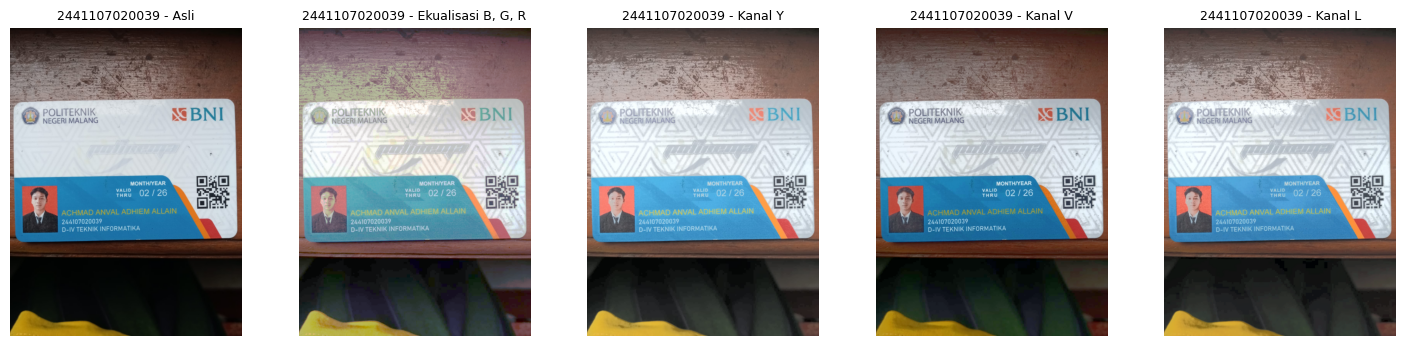

In [ ]:
judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
citra = [bgr, he_rgb, he_y, he_v, he_l]
plt.figure(figsize=(18, 4))
for i, (c, t) in enumerate(zip(citra, judul), 1):
 plt.subplot(1, 5, i)
 plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
 plt.title('2441107020039' + ' - ' + t, fontsize=9)
 plt.axis('off')
plt.show()

In [ ]:
def geser_hue(asli, hasil):
 h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
 h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
 d = np.abs(h1 - h2)
 d = np.minimum(d, 180 - d) # Hue melingkar 0-179
 return d.mean()
print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
for t, c in zip(judul, citra):
 print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2,
 cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))


Cara                    geser Hue (der)    rerata terang
Asli                               0.00            100.1
Ekualisasi B, G, R                42.21            128.7
Kanal Y                            0.52            128.7
Kanal V                            0.91            107.0
Kanal L                           10.54            123.1


 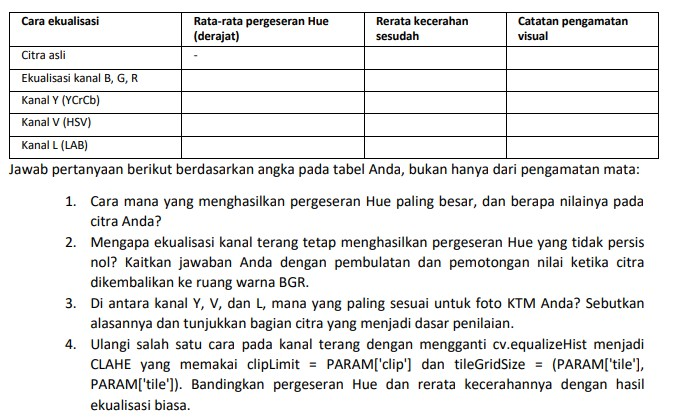

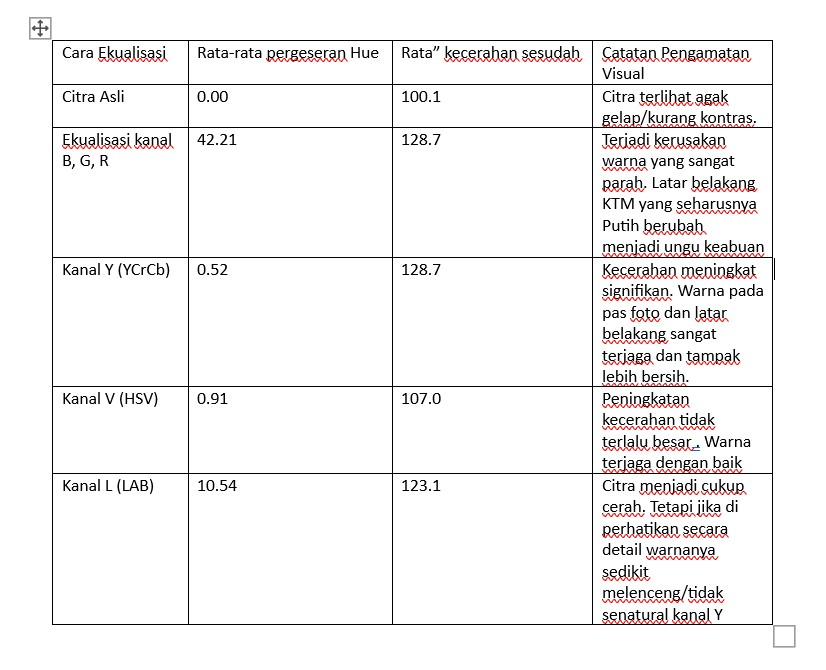

1. Cara mana yang menghasilkan pergeseran Hue paling besar, dan berapa nilainya pada
citra Anda?
2. Mengapa ekualisasi kanal terang tetap menghasilkan pergeseran Hue yang tidak persis
nol? Kaitkan jawaban Anda dengan pembulatan dan pemotongan nilai ketika citra
dikembalikan ke ruang warna BGR.
3. Di antara kanal Y, V, dan L, mana yang paling sesuai untuk foto KTM Anda? Sebutkan
alasannya dan tunjukkan bagian citra yang menjadi dasar penilaian.
4. Ulangi salah satu cara pada kanal terang dengan mengganti cv.equalizeHist menjadi
CLAHE yang memakai clipLimit = PARAM['clip'] dan tileGridSize = (PARAM['tile'],
PARAM['tile']). Bandingkan pergeseran Hue dan rerata kecerahannya dengan hasil
ekualisasi biasa.

jawaban
1. yang menghasilakan pergeseran Hue paling besar adalah Ekualisasi kanal B,G,R dengan nilai pergeseran 42.21 derajat. Hal ini terjadi karena histogram tiap kanal warna direnggangkan secara tersendiri, sehingga rasio antar warna penyusun citra rusal total dan enciptakan warna baru yang salah.

2. Pergeseran Hue tidak persis nol karena proses konversi kembali ke ruang warna BGR (format 8-bit) memaksa sistem untuk melakukan pembulatan nilai desimal menjadi bilangan bulat dan pemotongan (clipping) nilai yang berada di luar rentang 0–255. Penyesuaian paksa secara matematis inilah yang sedikit mengubah rasio murni antara warna Biru, Hijau, dan Merah (B, G, R), sehingga menyebabkan nilai Hue bergeser meskipun sangat kecil.


3. Kanal Y memberikan kombinasi terbaik dengan peningkatan kecerahan tertinggi menjadi 128.7 sekaligus mempertahankan warna asli paling akurat dengan pergeseran Hue paling kecil (hanya 0.52 derajat).



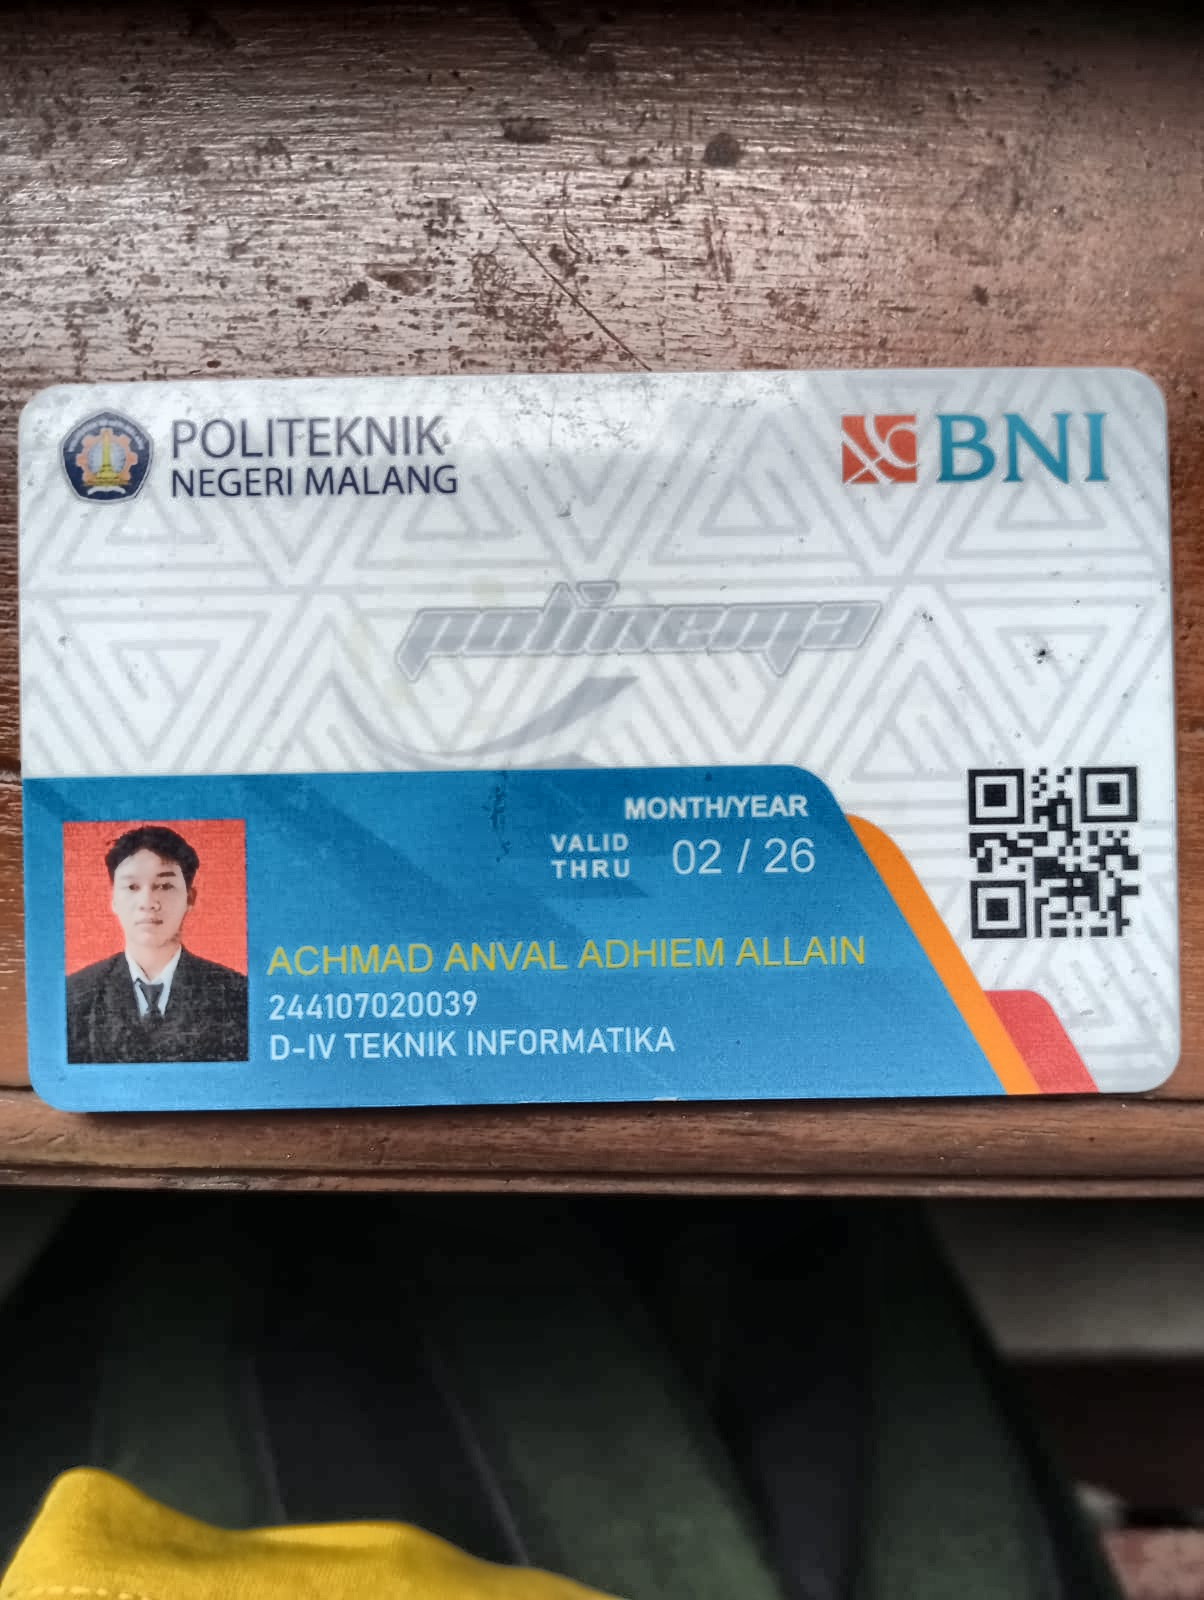

In [ ]:

clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
he_y_clahe = cv.cvtColor(cv.merge([clahe.apply(y), cr, cb]), cv.COLOR_YCrCb2BGR)

cv2_imshow(he_y_clahe)

rata rata kecerahan menjadi lebih stabil karena CLAHE membatasi amplifikasi kontras secara local hal tersebut terjadi karena Pergeseran Hue yang mungkin serupa atau sedikit lebih baik, namun dengan kualitas visual yang jauh lebih baik karena kontras berlebih dan gangguan visual (noise) di area background bisa diminimalisasi secara signifikan.

### E-3 Tugas Praktikum Dithering

In [ ]:

def floyd_steinberg(gray, L=2):
    # Simpan citra kerja sebagai float32 sebelum proses difusi error
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru # Hitung error

            # Difusi error ke tetangga (berdasarkan diagram Floyd-Steinberg)
            if x + 1 < W:
                img[y, x + 1] += error * (7 / 16)
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * (3 / 16)
            if y + 1 < H:
                img[y + 1, x] += error * (5 / 16)
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * (1 / 16)

    # Kembalikan ke format uint8 dengan nilai rentang 0-255
    return np.clip(img, 0, 255).astype(np.uint8)

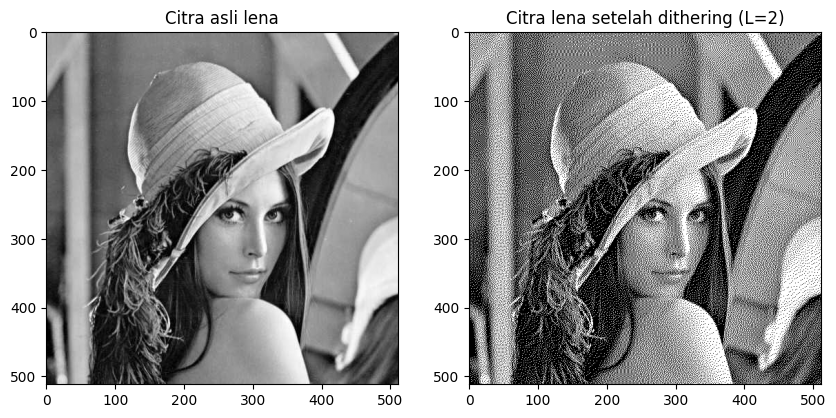

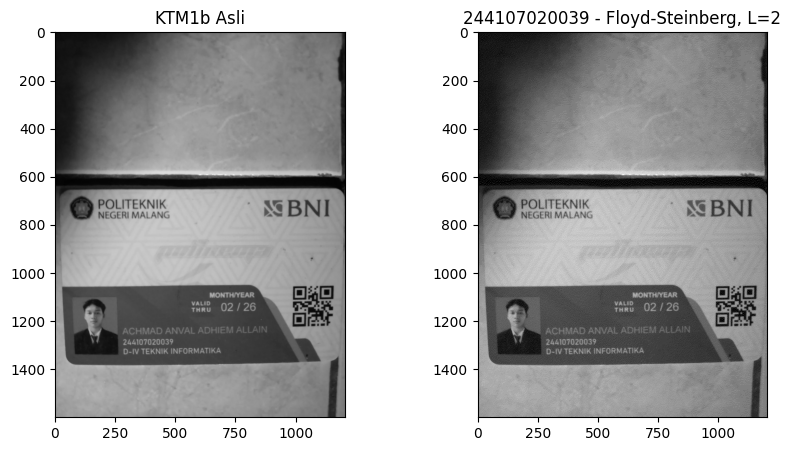

In [ ]:
# TAHAP 1: Uji coba dengan citra contoh lena.jpg
lena = cv.imread(FOTO + '/lena.jpg', cv.IMREAD_GRAYSCALE)
lena_dither = floyd_steinberg(lena, L=2)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(lena, cmap='gray'), plt.title('Citra asli lena')
plt.subplot(1, 2, 2), plt.imshow(lena_dither, cmap='gray'), plt.title('Citra lena setelah dithering (L=2)')
plt.show()

# TAHAP 2: Penerapan pada citra KTM1b.jpg dengan parameter L berbasis NIM
# Ganti nama 'KTM1b.jpg' jika nama file Anda berbeda
ktm_1b = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)

# Ambil nilai L dari dict PARAM yang sudah dihitung di sel identitas
L_val = PARAM['L']
ktm_1b_dither = floyd_steinberg(ktm_1b, L=L_val)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1), plt.imshow(ktm_1b, cmap='gray'), plt.title('KTM1b Asli')
plt.subplot(1, 2, 2), plt.imshow(ktm_1b_dither, cmap='gray'), plt.title(f'{244107020039} - Floyd-Steinberg, L={L_val}')
plt.show()

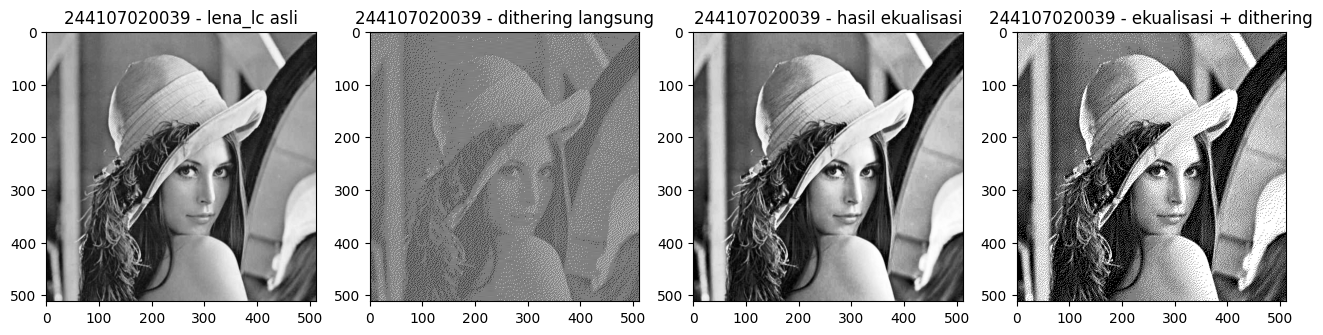

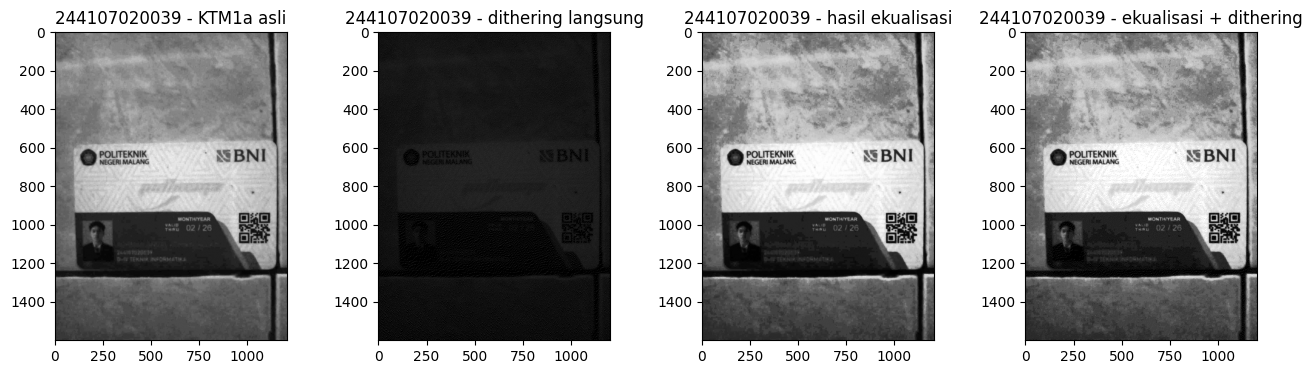

In [ ]:
# TAHAP 1: Uji coba dengan citra contoh lena_lc.jpg
lena_lc = cv.imread(FOTO + '/lena_lc.jpg', cv.IMREAD_GRAYSCALE)

# Dithering langsung vs Equalization + Dithering
lena_lc_dither_langsung = floyd_steinberg(lena_lc, L=2)
lena_lc_eq = cv.equalizeHist(lena_lc)
lena_lc_eq_dither = floyd_steinberg(lena_lc_eq, L=2)

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1), plt.imshow(lena_lc, cmap='gray'), plt.title(f'{NIM} - lena_lc asli')
plt.subplot(1, 4, 2), plt.imshow(lena_lc_dither_langsung, cmap='gray'), plt.title(f'{NIM} - dithering langsung')
plt.subplot(1, 4, 3), plt.imshow(lena_lc_eq, cmap='gray'), plt.title(f'{NIM} - hasil ekualisasi')
plt.subplot(1, 4, 4), plt.imshow(lena_lc_eq_dither, cmap='gray'), plt.title(f'{NIM} - ekualisasi + dithering')
plt.show()

# TAHAP 2: Penerapan pada citra KTM1a.jpg (Kondisi Gelap)
ktm_1a = cv.imread(KTM + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)

# Dithering langsung vs Equalization + Dithering
ktm_1a_dither_langsung = floyd_steinberg(ktm_1a, L=L_val)
ktm_1a_eq = cv.equalizeHist(ktm_1a)
ktm_1a_eq_dither = floyd_steinberg(ktm_1a_eq, L=L_val)

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1), plt.imshow(ktm_1a, cmap='gray'), plt.title(f'{NIM} - KTM1a asli')
plt.subplot(1, 4, 2), plt.imshow(ktm_1a_dither_langsung, cmap='gray'), plt.title(f'{NIM} - dithering langsung')
plt.subplot(1, 4, 3), plt.imshow(ktm_1a_eq, cmap='gray'), plt.title(f'{NIM} - hasil ekualisasi')
plt.subplot(1, 4, 4), plt.imshow(ktm_1a_eq_dither, cmap='gray'), plt.title(f'{NIM} - ekualisasi + dithering')
plt.show()